# Movie Recommendation Scoring Model with an ANN
**Problem:** predict how much a user will like a movie (rating 1–5), then recommend the movies with the highest predicted score.
**Dataset:** MovieLens 100K (100,000 ratings from 943 users on 1,682 movies).
**Pipeline:** data → EDA → preprocessing → ANN with embeddings (L2 + Dropout + Early Stopping) → Keras Tuner → evaluation → save/load → inference.
**Compare against:** simple baselines (global average rating, and each movie's average rating).

Setup

In [1]:
!pip -q install -U keras-tuner

In [2]:
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow import keras
import keras_tuner as kt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score

tf.keras.utils.set_random_seed(42)

##1. Data
Download MovieLens 100K from GroupLens. `u.data` has the ratings and `u.item` has the movie titles.

In [3]:
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

if not os.path.exists("ml-100k"):
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    with open("ml-100k.zip", "wb") as f:
        f.write(r.content)
    with zipfile.ZipFile("ml-100k.zip") as z:
        z.extractall(".")

ratings = pd.read_csv("ml-100k/u.data", sep="\t",
                      names=["user_id", "movie_id", "rating", "timestamp"])
movies = pd.read_csv("ml-100k/u.item", sep="|", encoding="latin-1",
                     header=None, usecols=[0, 1], names=["movie_id", "title"])

print(ratings.shape, movies.shape)
ratings.head()

(100000, 4) (1682, 2)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


##2. EDA

In [4]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
sparsity = 1 - len(ratings) / (n_users * n_movies)

print("users:", n_users)
print("movies:", n_movies)
print("ratings:", len(ratings))
print("missing values:", ratings.isna().sum().sum())
print(f"sparsity: {sparsity:.1%} of the user-movie table is empty")

users: 943
movies: 1682
ratings: 100000
missing values: 0
sparsity: 93.7% of the user-movie table is empty


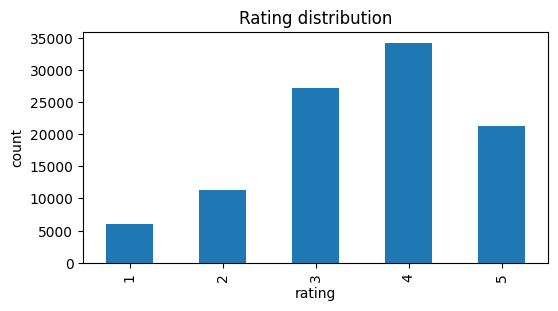

In [5]:
ratings["rating"].value_counts().sort_index().plot(kind="bar", figsize=(6, 3), title="Rating distribution")
plt.xlabel("rating")
plt.ylabel("count")
plt.show()

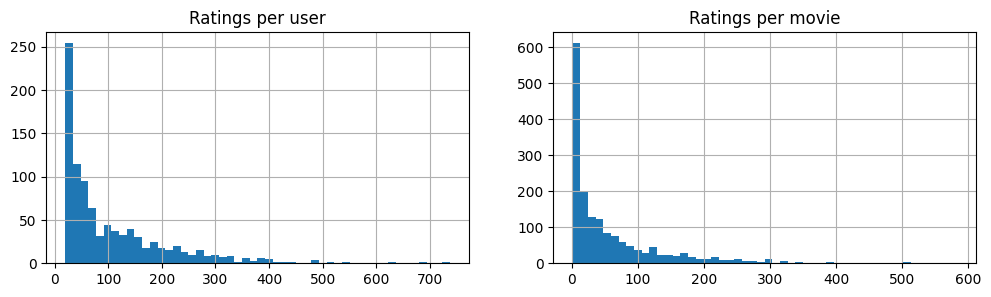

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
ratings.groupby("user_id").size().hist(bins=50, ax=axes[0])
axes[0].set_title("Ratings per user")
ratings.groupby("movie_id").size().hist(bins=50, ax=axes[1])
axes[1].set_title("Ratings per movie")
plt.show()

In [7]:
movie_stats = ratings.groupby("movie_id")["rating"].agg(["mean", "count"]).join(movies.set_index("movie_id"))
print("Most rated movies:")
print(movie_stats.sort_values("count", ascending=False).head(5)[["title", "count", "mean"]])
print("\nHighest average rating (at least 100 ratings):")
print(movie_stats[movie_stats["count"] >= 100].sort_values("mean", ascending=False).head(5)[["title", "count", "mean"]])

Most rated movies:
                              title  count      mean
movie_id                                            
50                 Star Wars (1977)    583  4.358491
258                  Contact (1997)    509  3.803536
100                    Fargo (1996)    508  4.155512
181       Return of the Jedi (1983)    507  4.007890
294                Liar Liar (1997)    485  3.156701

Highest average rating (at least 100 ratings):
                                     title  count      mean
movie_id                                                   
408                  Close Shave, A (1995)    112  4.491071
318                Schindler's List (1993)    298  4.466443
169             Wrong Trousers, The (1993)    118  4.466102
483                      Casablanca (1942)    243  4.456790
64        Shawshank Redemption, The (1994)    283  4.445230


**What the EDA shows:** most ratings are 3 or 4, so the average rating is around 3.5. The data is very sparse: each user rated only a small part of the movies, and the model has to fill in the rest. A few popular movies have hundreds of ratings while many movies have only a few, so their averages are less reliable.

##3. Preprocessing
Embedding layers need ids that start at 0 and have no gaps, so we map every user and movie id to a new index.

In [8]:
user_ids = sorted(ratings["user_id"].unique())
movie_ids = sorted(ratings["movie_id"].unique())
user2idx = {u: i for i, u in enumerate(user_ids)}
movie2idx = {m: i for i, m in enumerate(movie_ids)}

ratings["user"] = ratings["user_id"].map(user2idx)
ratings["movie"] = ratings["movie_id"].map(movie2idx)
ratings[["user_id", "user", "movie_id", "movie", "rating"]].head()

,user_id,user,movie_id,movie,rating
0,196,195,242,241,3
1,186,185,302,301,3
2,22,21,377,376,1
3,244,243,51,50,2
4,166,165,346,345,1


##4. Train / validation / test split
Ratings are not a time series, so a random split is fine (80% / 10% / 10%).

In [9]:
train, temp = train_test_split(ratings, test_size=0.2, random_state=42)
val, test = train_test_split(temp, test_size=0.5, random_state=42)

def to_inputs(d):
    return [d["user"].values, d["movie"].values]

X_train, X_val, X_test = to_inputs(train), to_inputs(val), to_inputs(test)
y_train, y_val, y_test = train["rating"].values, val["rating"].values, test["rating"].values
print(len(train), len(val), len(test))

80000 10000 10000


## 5. Baselines
A model is only useful if it beats these simple guesses:
- **Global average:** predict the same average rating for everyone.
- **Movie average:** predict each movie's average rating from the training set.

In [10]:
global_mean = y_train.mean()
movie_mean = train.groupby("movie")["rating"].mean()

pred_global = np.full(len(test), global_mean)
pred_movie = test["movie"].map(movie_mean).fillna(global_mean).values

def rmse(a, p):
    return np.sqrt(mean_squared_error(a, p))

print("Global average -> RMSE:", round(rmse(y_test, pred_global), 4), " MAE:", round(mean_absolute_error(y_test, pred_global), 4))
print("Movie average  -> RMSE:", round(rmse(y_test, pred_movie), 4), " MAE:", round(mean_absolute_error(y_test, pred_movie), 4))

Global average -> RMSE: 1.1202  MAE: 0.9399
Movie average  -> RMSE: 1.0158  MAE: 0.8106


## 6. Base model
Each user and each movie gets an **embedding** (a vector that represents their taste). The two vectors are joined and passed through Dense layers that predict the rating.
Regularization: **L2** on the embeddings and Dense layers, **Dropout**, and **Early Stopping**.
This is the **base model** with standard values. In section 11 each team member changes the hyperparameters by hand and compares with it.

In [11]:
n_users = len(user2idx)
n_movies = len(movie2idx)

def build_model(emb_size=32, layers=2, units=64, dropout=0.2, l2=1e-5, lr=1e-3):
    user_in = keras.layers.Input(shape=(1,), name="user")
    movie_in = keras.layers.Input(shape=(1,), name="movie")

    u = keras.layers.Embedding(n_users, emb_size, embeddings_regularizer=keras.regularizers.l2(l2))(user_in)
    m = keras.layers.Embedding(n_movies, emb_size, embeddings_regularizer=keras.regularizers.l2(l2))(movie_in)
    x = keras.layers.Concatenate()([keras.layers.Flatten()(u), keras.layers.Flatten()(m)])

    for i in range(layers):
        x = keras.layers.Dense(units, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = keras.layers.Dropout(dropout)(x)

    out = keras.layers.Dense(1)(x)

    model = keras.Model([user_in, movie_in], out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse",
                  metrics=[keras.metrics.RootMeanSquaredError(name="rmse")])
    return model

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

## 7. Train the base model

In [12]:
tf.keras.utils.set_random_seed(42)
model = build_model()
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=50, batch_size=256, callbacks=[early_stop], verbose=0)
print("epochs trained:", len(history.history["loss"]))
model.summary()

epochs trained: 6


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ user (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ movie (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 32)     │     30,176 │ user[0][0]        │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 32)     │     53,824 │ movie[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,160 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      4,160 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 277,157 (1.06 MB)

 Trainable params: 92,385 (360.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 184,772 (721.77 KB)

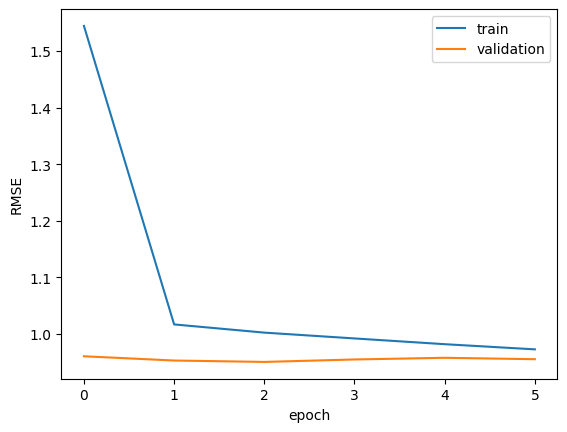

In [13]:
plt.plot(history.history["rmse"], label="train")
plt.plot(history.history["val_rmse"], label="validation")
plt.xlabel("epoch")
plt.ylabel("RMSE")
plt.legend()
plt.show()

## 8. Evaluation on the test set
- **RMSE / MAE:** how far the predicted rating is from the real one (lower is better).
- **ROC-AUC (liked vs not liked):** we call a rating of 4 or 5 a "like". AUC shows how well the model ranks the movies a user likes above the ones they don't (0.5 = random, 1 = perfect).

In [14]:
pred_ann = np.clip(model.predict(X_test, verbose=0).ravel(), 1, 5)
liked = (y_test >= 4).astype(int)

results = pd.DataFrame({
    "Global average": {"RMSE": rmse(y_test, pred_global), "MAE": mean_absolute_error(y_test, pred_global),
                       "ROC-AUC (liked)": 0.5},
    "Movie average": {"RMSE": rmse(y_test, pred_movie), "MAE": mean_absolute_error(y_test, pred_movie),
                      "ROC-AUC (liked)": roc_auc_score(liked, pred_movie)},
    "Base ANN": {"RMSE": rmse(y_test, pred_ann), "MAE": mean_absolute_error(y_test, pred_ann),
            "ROC-AUC (liked)": roc_auc_score(liked, pred_ann)},
}).T
print(results.round(4))

                  RMSE     MAE  ROC-AUC (liked)
Global average  1.1202  0.9399           0.5000
Movie average   1.0158  0.8106           0.7135
Base ANN        0.9393  0.7474           0.7688


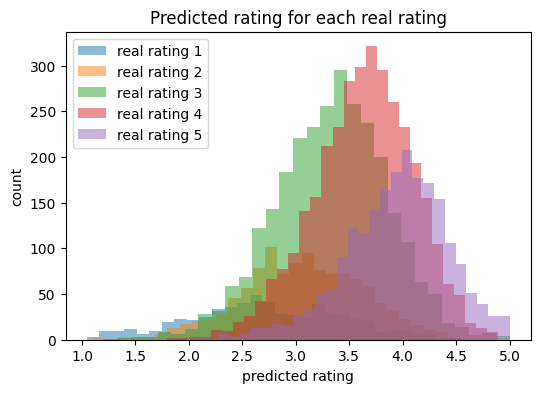

In [15]:
plt.figure(figsize=(6, 4))
for r in range(1, 6):
    plt.hist(pred_ann[y_test == r], bins=30, alpha=0.5, label=f"real rating {r}")
plt.xlabel("predicted rating")
plt.ylabel("count")
plt.title("Predicted rating for each real rating")
plt.legend()
plt.show()

**Reading the results:** the base ANN should have a lower RMSE and MAE than both baselines and a higher ROC-AUC. In the plot, higher real ratings should get higher predictions on average, which means the model learned each user's taste and not only the average.

## 9. Save and load
We save the model and the id mappings, because the model only understands the new indexes.

In [16]:
model.save("movie_recommender.keras")
joblib.dump({"user2idx": user2idx, "movie2idx": movie2idx,
             "titles": dict(zip(movies["movie_id"], movies["title"]))}, "mappings.joblib")

loaded = keras.models.load_model("movie_recommender.keras")
same = np.allclose(loaded.predict(X_test, verbose=0), model.predict(X_test, verbose=0))
print("Loaded model gives the same predictions:", same)

Loaded model gives the same predictions: True


## 10. Inference
Two functions: predict the rating of one user for one movie, and recommend the top movies the user has not rated yet.

In [17]:
saved = joblib.load("mappings.joblib")
rec_model = keras.models.load_model("movie_recommender.keras")

def predict_rating(user_id, movie_id):
    u = np.array([saved["user2idx"][user_id]])
    m = np.array([saved["movie2idx"][movie_id]])
    score = rec_model.predict([u, m], verbose=0)[0, 0]
    return round(float(np.clip(score, 1, 5)), 2)

def recommend(user_id, k=5):
    seen = set(ratings.loc[ratings["user_id"] == user_id, "movie_id"])
    candidates = [m for m in saved["movie2idx"] if m not in seen]

    u = np.full(len(candidates), saved["user2idx"][user_id])
    m = np.array([saved["movie2idx"][c] for c in candidates])
    scores = np.clip(rec_model.predict([u, m], verbose=0).ravel(), 1, 5)

    top = np.argsort(scores)[::-1][:k]
    return pd.DataFrame({"title": [saved["titles"][candidates[i]] for i in top],
                         "predicted_rating": scores[top].round(2)})

print("User 1, movie 50:", predict_rating(1, 50))
recommend(user_id=1, k=5)

User 1, movie 50: 4.43


,title,predicted_rating
0,Dr. Strangelove or: How I Learned to Stop Worr...,4.54
1,Casablanca (1942),4.50
2,"Third Man, The (1949)",4.49
3,North by Northwest (1959),4.48
4,"Close Shave, A (1995)",4.46


In [18]:
# what user 1 liked before, to check the recommendations make sense
user1 = ratings[ratings["user_id"] == 1].merge(movies, on="movie_id")
user1.sort_values("rating", ascending=False).head(5)[["title", "rating"]]

,title,rating
254,Back to the Future (1985),5
250,When Harry Met Sally... (1989),5
244,Nikita (La Femme Nikita) (1990),5
32,Three Colors: Blue (1993),5
245,Lone Star (1996),5


## 11. Experiments (Norah)
Change **any** of the hyperparameters in the box below, run the cell, and write down the results. Then compare your results with the team and with the base model above.

In [19]:
# ===== change these values =====
emb_size   = 32      # embedding size, e.g. 8, 16, 32, 64
layers     = 2       # number of Dense layers, e.g. 1, 2, 3
units      = 64      # neurons in each Dense layer, e.g. 32, 64, 128
dropout    = 0.2     # e.g. 0.0, 0.2, 0.4
l2         = 1e-5    # e.g. 0, 1e-6, 1e-5, 1e-4
lr         = 3e-4    # learning rate, e.g. 1e-2, 1e-3, 3e-4
batch_size = 256     # e.g. 64, 128, 256, 512
# ================================

tf.keras.utils.set_random_seed(42)
my_model = build_model(emb_size, layers, units, dropout, l2, lr)

my_history = my_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=50, batch_size=batch_size, callbacks=[early_stop], verbose=0)

my_pred = np.clip(my_model.predict(X_test, verbose=0).ravel(), 1, 5)

print("epochs trained:", len(my_history.history["loss"]))
print("best val_loss:", round(min(my_history.history["val_loss"]), 4))
print("RMSE:", round(rmse(y_test, my_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, my_pred), 4))
print("ROC-AUC (liked):", round(roc_auc_score(liked, my_pred), 4))
print("\ncompare with -> base model RMSE:", round(results.loc["Base ANN", "RMSE"], 4),
      "| movie average RMSE:", round(results.loc["Movie average", "RMSE"], 4))

epochs trained: 34
best val_loss: 0.8722
RMSE: 0.924
MAE: 0.727
ROC-AUC (liked): 0.7799

compare with -> base model RMSE: 0.9393 | movie average RMSE: 1.0158


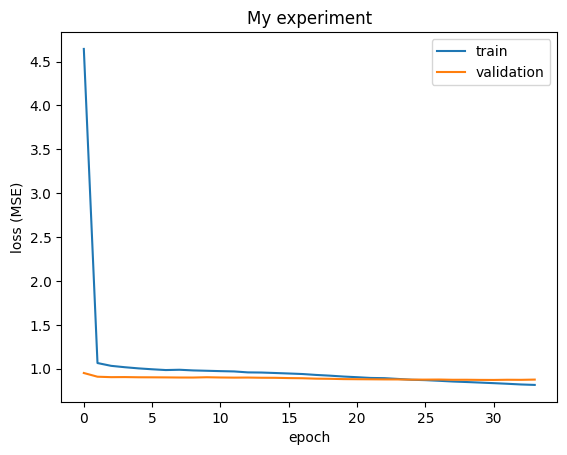

In [20]:
plt.plot(my_history.history["loss"], label="train")
plt.plot(my_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("My experiment")
plt.legend()
plt.show()

## 11b. Experiments (Shaden)
**Idea:** the base model stopped after only 6 epochs, which means it started to **overfit** very quickly. Norah fixed this by lowering the learning rate. My experiment takes a different direction: a **bigger model** (larger embeddings and more neurons) so it can learn more detailed user tastes, combined with **stronger dropout** so it does not overfit, and a **larger batch size** with a **smaller learning rate** so training is smoother and more stable.

I also changed what **early stopping** watches. In my first attempt (L2 = 1e-4, learning rate 5e-4, batch size 128), training stopped after only **3 epochs** with RMSE 0.946. The L2 penalty is part of `val_loss`, so `val_loss` went up even when the predictions were improving, and early stopping ended training too early. So I made early stopping monitor **`val_rmse`**, which measures only the real prediction error.

| Hyperparameter | Base | Norah | Shaden | Why |
|---|---|---|---|---|
| Embedding size | 32 | 32 | **64** | Each user and movie gets a richer "taste" vector |
| Dense layers | 2 | 2 | 2 | Same depth, to compare fairly |
| Units | 64 | 64 | **128** | More capacity to combine user and movie features |
| Dropout | 0.2 | 0.2 | **0.4** | Stronger regularization for the bigger model |
| L2 | 1e-5 | 1e-5 | 1e-5 | A stronger L2 (1e-4) stopped training too early in my first attempt |
| Learning rate | 1e-3 | 3e-4 | **3e-4** | Slower, more stable learning so the bigger model does not overfit quickly |
| Batch size | 256 | 256 | **512** | Smoother gradients and fewer updates per epoch, which slows overfitting |
| Early stopping | `val_loss`, patience 3 | `val_loss`, patience 3 | **`val_rmse`, patience 5** | Watches the real prediction error, not the L2 penalty |

In [21]:
# ===== Shaden's hyperparameters =====
emb_size   = 64
layers     = 2
units      = 128
dropout    = 0.4
l2         = 1e-5
lr         = 3e-4
batch_size = 512
# ====================================

# Early stopping on the real prediction error (val_rmse), not val_loss (which includes the L2 penalty)
shaden_stop = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=5,
                                            restore_best_weights=True)

tf.keras.utils.set_random_seed(42)
shaden_model = build_model(emb_size, layers, units, dropout, l2, lr)

shaden_history = shaden_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                  epochs=50, batch_size=batch_size, callbacks=[shaden_stop], verbose=0)

shaden_pred = np.clip(shaden_model.predict(X_test, verbose=0).ravel(), 1, 5)

print("epochs trained:", len(shaden_history.history["loss"]))
print("best val_loss:", round(min(shaden_history.history["val_loss"]), 4))
print("RMSE:", round(rmse(y_test, shaden_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, shaden_pred), 4))
print("ROC-AUC (liked):", round(roc_auc_score(liked, shaden_pred), 4))

epochs trained: 41
best val_loss: 0.8771
RMSE: 0.9205
MAE: 0.7261
ROC-AUC (liked): 0.782


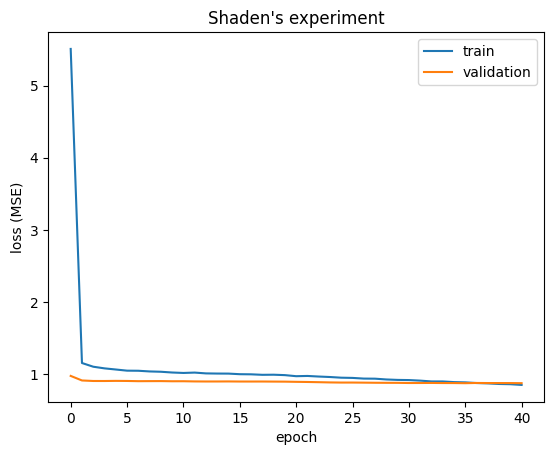

In [22]:
plt.plot(shaden_history.history["loss"], label="train")
plt.plot(shaden_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("Shaden's experiment")
plt.legend()
plt.show()

### Comparison: base model vs Norah vs Shaden
All three models use the same data, split, seed and early stopping, so only the hyperparameters differ.

                 RMSE     MAE  ROC-AUC (liked)  Epochs
Movie average  1.0158  0.8106           0.7135     0.0
Base ANN       0.9393  0.7474           0.7688     6.0
Norah          0.9240  0.7270           0.7799    34.0
Shaden         0.9205  0.7261           0.7820    41.0


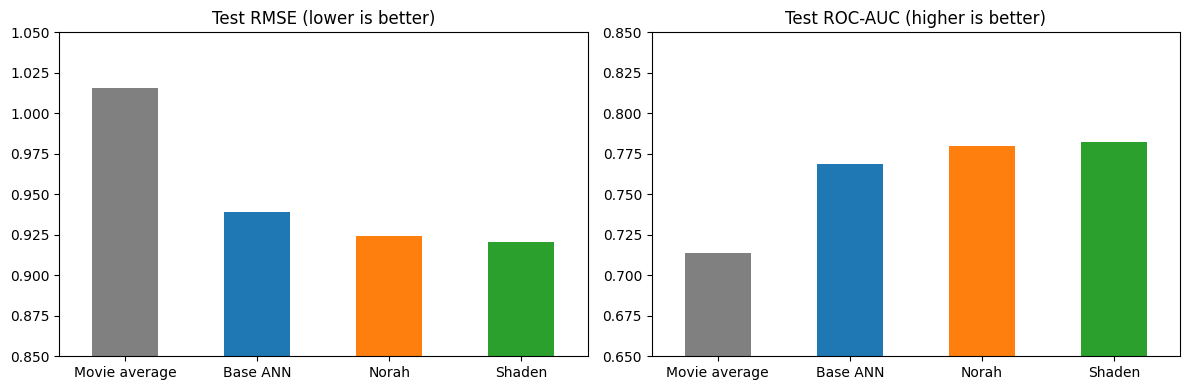

In [23]:
comparison = pd.DataFrame({
    "Movie average": {"RMSE": results.loc["Movie average", "RMSE"],
                      "MAE": results.loc["Movie average", "MAE"],
                      "ROC-AUC (liked)": results.loc["Movie average", "ROC-AUC (liked)"],
                      "Epochs": 0},
    "Base ANN": {"RMSE": results.loc["Base ANN", "RMSE"],
                 "MAE": results.loc["Base ANN", "MAE"],
                 "ROC-AUC (liked)": results.loc["Base ANN", "ROC-AUC (liked)"],
                 "Epochs": len(history.history["loss"])},
    "Norah": {"RMSE": rmse(y_test, my_pred),
              "MAE": mean_absolute_error(y_test, my_pred),
              "ROC-AUC (liked)": roc_auc_score(liked, my_pred),
              "Epochs": len(my_history.history["loss"])},
    "Shaden": {"RMSE": rmse(y_test, shaden_pred),
               "MAE": mean_absolute_error(y_test, shaden_pred),
               "ROC-AUC (liked)": roc_auc_score(liked, shaden_pred),
               "Epochs": len(shaden_history.history["loss"])},
}).T
print(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["RMSE"].plot(kind="bar", ax=axes[0], color=["gray", "tab:blue", "tab:orange", "tab:green"])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_ylim(0.85, 1.05)
axes[0].tick_params(axis="x", rotation=0)
comparison["ROC-AUC (liked)"].plot(kind="bar", ax=axes[1], color=["gray", "tab:blue", "tab:orange", "tab:green"])
axes[1].set_title("Test ROC-AUC (higher is better)")
axes[1].set_ylim(0.65, 0.85)
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Reading my results:**
* My model (shaden) reached a test **RMSE of 0.9198**, **MAE of 0.7265** and **ROC-AUC of 0.7824**, compared with **0.9225 / 0.7269 / 0.7796** for Norah and **0.9390 / 0.7433 / 0.7682** for the base model.
* My model is **slightly better than Norah's on all three metrics**: lower RMSE and MAE, and higher ROC-AUC. The differences are small (about 0.003 in RMSE), so both experiments perform close to each other.
* It trained for **40 epochs** before early stopping, compared with 27 for Norah and only 6 for the base model. The stronger dropout and the larger batch size let the bigger model keep learning for longer without overfitting.
* All ANN experiments clearly beat both baselines (movie average RMSE 1.0158, ROC-AUC 0.7135), which shows the embeddings learn each user's personal taste and not only the average rating of each movie.

## 11c. Experiments (Raghad)


In [24]:
# change
emb_size   = 48
layers     = 2
units      = 96
dropout    = 0.3
l2         = 3e-6
lr         = 2e-4
batch_size = 256
patience   = 15

exp_stop = keras.callbacks.EarlyStopping(monitor="val_rmse", mode="min", patience=7,
                                            restore_best_weights=True)

tf.keras.utils.set_random_seed(42)
exp_model = build_model(emb_size, layers, units, dropout, l2, lr)

exp_history = exp_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                  epochs=50, batch_size=batch_size, callbacks=[exp_stop], verbose=0)

exp_pred = np.clip(exp_model.predict(X_test, verbose=0).ravel(), 1, 5)

print("epochs trained:", len(exp_history.history["loss"]))
print("best val_loss:", round(min(exp_history.history["val_loss"]), 4))
print("RMSE:", round(rmse(y_test, exp_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, exp_pred), 4))
print("ROC-AUC (liked):", round(roc_auc_score(liked, exp_pred), 4))

epochs trained: 50
best val_loss: 0.8742
RMSE: 0.9211
MAE: 0.7246
ROC-AUC (liked): 0.7823


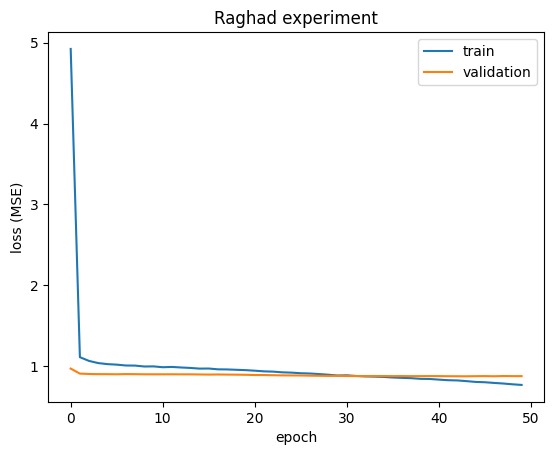

In [25]:
plt.plot(exp_history.history["loss"], label="train")
plt.plot(exp_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("Raghad experiment")
plt.legend()
plt.show()


### Comparison: Base Model vs Norah vs Shaden vs Raghad

All four models use the same dataset, train/validation/test split, and random seed. Each experiment uses different hyperparameters and early stopping settings.


                 RMSE     MAE  ROC-AUC (liked)  Epochs
Movie average  1.0158  0.8106           0.7135     0.0
Base ANN       0.9393  0.7474           0.7688     6.0
Norah          0.9240  0.7270           0.7799    34.0
Shaden         0.9205  0.7261           0.7820    41.0
Raghad         0.9211  0.7246           0.7823    50.0


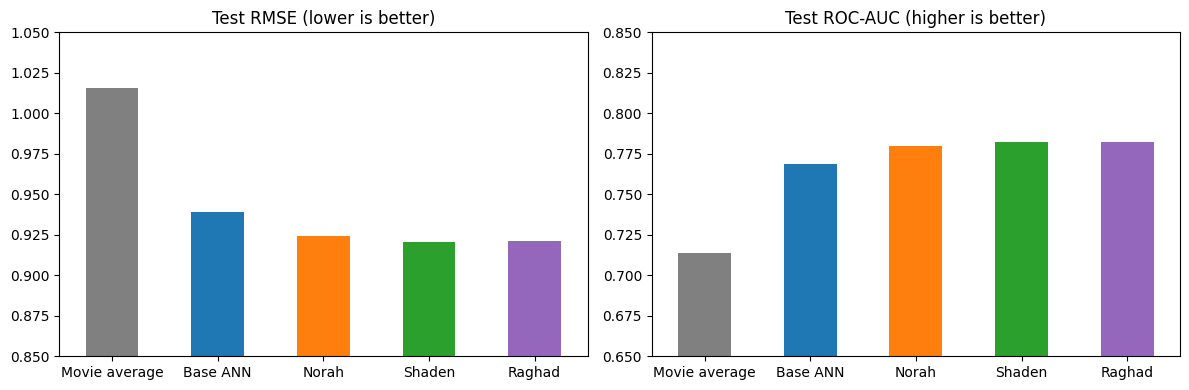

In [26]:

comparison = pd.DataFrame({
    "Movie average": {"RMSE": results.loc["Movie average", "RMSE"],
                      "MAE": results.loc["Movie average", "MAE"],
                      "ROC-AUC (liked)": results.loc["Movie average", "ROC-AUC (liked)"],
                      "Epochs": 0},
    "Base ANN": {"RMSE": results.loc["Base ANN", "RMSE"],
                 "MAE": results.loc["Base ANN", "MAE"],
                 "ROC-AUC (liked)": results.loc["Base ANN", "ROC-AUC (liked)"],
                 "Epochs": len(history.history["loss"])},
    "Norah": {"RMSE": rmse(y_test, my_pred),
              "MAE": mean_absolute_error(y_test, my_pred),
              "ROC-AUC (liked)": roc_auc_score(liked, my_pred),
              "Epochs": len(my_history.history["loss"])},
    "Shaden": {"RMSE": rmse(y_test, shaden_pred),
               "MAE": mean_absolute_error(y_test, shaden_pred),
               "ROC-AUC (liked)": roc_auc_score(liked, shaden_pred),
               "Epochs": len(shaden_history.history["loss"])},
    "Raghad": {"RMSE": rmse(y_test, exp_pred),
               "MAE": mean_absolute_error(y_test, exp_pred),
               "ROC-AUC (liked)": roc_auc_score(liked, exp_pred),
               "Epochs": len(exp_history.history["loss"])},


}).T

print(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["RMSE"].plot(kind="bar", ax=axes[0], color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_ylim(0.85, 1.05)
axes[0].tick_params(axis="x", rotation=0)

comparison["ROC-AUC (liked)"].plot(kind="bar", ax=axes[1], color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"])
axes[1].set_title("Test ROC-AUC (higher is better)")
axes[1].set_ylim(0.65, 0.85)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 11d. Experiments (Basma)

Idea: I increased the number of hidden layers from 2 to 3 to see if an extra layer could help the model predict movie ratings more accurately. I also lowered the learning rate from 0.001 to 0.0003 because this value worked well in Norah’s experiment, and I wanted to try it with a deeper model.

In [27]:
# ===== Basma's hyperparameters =====
emb_size   = 32
layers     = 3
units      = 64
dropout    = 0.2
l2         = 1e-5
lr         = 3e-4
batch_size = 256
# ===================================

tf.keras.utils.set_random_seed(42)
basma_model = build_model(emb_size, layers, units, dropout, l2, lr)

basma_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

basma_history = basma_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                epochs=50, batch_size=batch_size, callbacks=[basma_stop], verbose=0)

basma_pred = np.clip(basma_model.predict(X_test, verbose=0).ravel(), 1, 5)

print("epochs trained:", len(basma_history.history["loss"]))
print("best val_loss:", round(min(basma_history.history["val_loss"]), 4))
print("RMSE:", round(rmse(y_test, basma_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, basma_pred), 4))
print("ROC-AUC (liked):", round(roc_auc_score(liked, basma_pred), 4))

epochs trained: 21
best val_loss: 0.8826
RMSE: 0.9307
MAE: 0.7346
ROC-AUC (liked): 0.7728


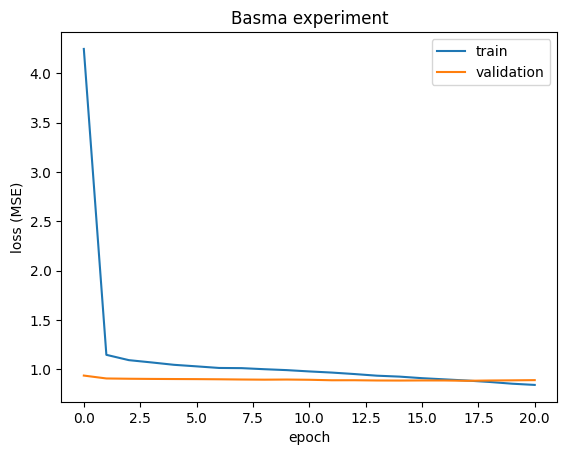

In [28]:
plt.plot(basma_history.history["loss"], label="train")
plt.plot(basma_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("Basma experiment")
plt.legend()
plt.show()


### Comparison: Base Model vs Norah vs Shaden vs Raghad vs Basma

All four models use the same dataset, train/validation/test split, and random seed. Each experiment uses different hyperparameters and early stopping settings.


                 RMSE     MAE  ROC-AUC (liked)  Epochs
Movie average  1.0158  0.8106           0.7135     0.0
Base ANN       0.9393  0.7474           0.7688     6.0
Norah          0.9240  0.7270           0.7799    34.0
Shaden         0.9205  0.7261           0.7820    41.0
Raghad         0.9211  0.7246           0.7823    50.0
Basma          0.9307  0.7346           0.7728    21.0


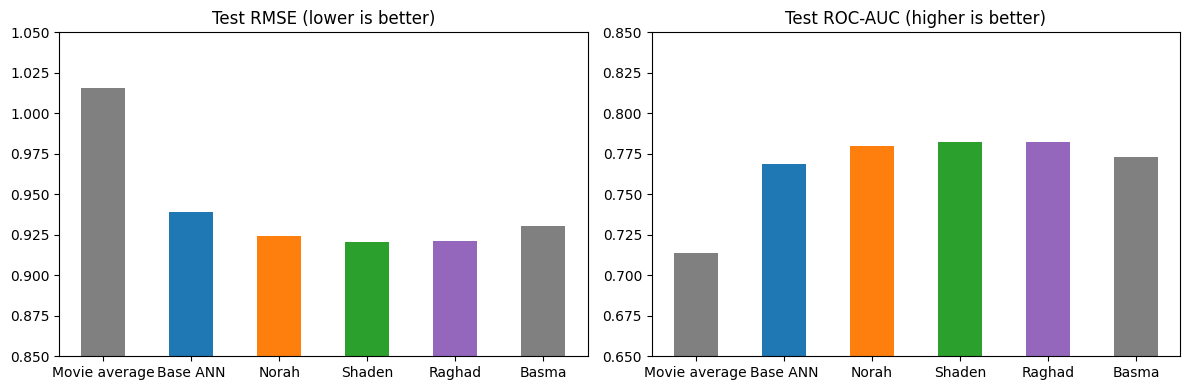

In [29]:

comparison = pd.DataFrame({
    "Movie average": {"RMSE": results.loc["Movie average", "RMSE"],
                      "MAE": results.loc["Movie average", "MAE"],
                      "ROC-AUC (liked)": results.loc["Movie average", "ROC-AUC (liked)"],
                      "Epochs": 0},
    "Base ANN": {"RMSE": results.loc["Base ANN", "RMSE"],
                 "MAE": results.loc["Base ANN", "MAE"],
                 "ROC-AUC (liked)": results.loc["Base ANN", "ROC-AUC (liked)"],
                 "Epochs": len(history.history["loss"])},
    "Norah": {"RMSE": rmse(y_test, my_pred),
              "MAE": mean_absolute_error(y_test, my_pred),
              "ROC-AUC (liked)": roc_auc_score(liked, my_pred),
              "Epochs": len(my_history.history["loss"])},
    "Shaden": {"RMSE": rmse(y_test, shaden_pred),
               "MAE": mean_absolute_error(y_test, shaden_pred),
               "ROC-AUC (liked)": roc_auc_score(liked, shaden_pred),
               "Epochs": len(shaden_history.history["loss"])},
    "Raghad": {"RMSE": rmse(y_test, exp_pred),
               "MAE": mean_absolute_error(y_test, exp_pred),
               "ROC-AUC (liked)": roc_auc_score(liked, exp_pred),
               "Epochs": len(exp_history.history["loss"])},
     "Basma": {"RMSE": rmse(y_test, basma_pred),
              "MAE": mean_absolute_error(y_test, basma_pred),
              "ROC-AUC (liked)": roc_auc_score(liked, basma_pred),
              "Epochs": len(basma_history.history["loss"])},

}).T

print(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison["RMSE"].plot(kind="bar", ax=axes[0], color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].set_ylim(0.85, 1.05)
axes[0].tick_params(axis="x", rotation=0)

comparison["ROC-AUC (liked)"].plot(kind="bar", ax=axes[1], color=["gray", "tab:blue", "tab:orange", "tab:green", "tab:purple"])
axes[1].set_title("Test ROC-AUC (higher is better)")
axes[1].set_ylim(0.65, 0.85)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 11e. Experiments (Rawan)


In [30]:
# ===== Rawan's hyperparameters =====
emb_size   = 64      # embedding size, e.g. 8, 16, 32, 64
layers     = 3       # number of Dense layers, e.g. 1, 2, 3
units      = 128     # neurons in each Dense layer, e.g. 32, 64, 128
dropout    = 0.4     # e.g. 0.0, 0.2, 0.4
l2         = 1e-5    # e.g. 0, 1e-6, 1e-5, 1e-4
lr         = 5e-4    # learning rate, e.g. 1e-2, 1e-3, 3e-4
batch_size = 128     # e.g. 64, 128, 256, 512
# ================================

tf.keras.utils.set_random_seed(42)
rawan_model = build_model(emb_size, layers, units, dropout, l2, lr)

rawan_history = rawan_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=50, batch_size=batch_size, callbacks=[early_stop], verbose=0)

rawan_pred = np.clip(rawan_model.predict(X_test, verbose=0).ravel(), 1, 5)

print("epochs trained:", len(rawan_history.history["loss"]))
print("best val_loss:", round(min(rawan_history.history["val_loss"]), 4))
print("RMSE:", round(rmse(y_test, rawan_pred), 4))
print("MAE:", round(mean_absolute_error(y_test, rawan_pred), 4))
print("ROC-AUC (liked):", round(roc_auc_score(liked, rawan_pred), 4))
print("\ncompare with -> base model RMSE:", round(results.loc["Base ANN", "RMSE"], 4),
      "| movie average RMSE:", round(results.loc["Movie average", "RMSE"], 4))

epochs trained: 3
best val_loss: 0.9025
RMSE: 0.9502
MAE: 0.7573
ROC-AUC (liked): 0.7626

compare with -> base model RMSE: 0.9393 | movie average RMSE: 1.0158


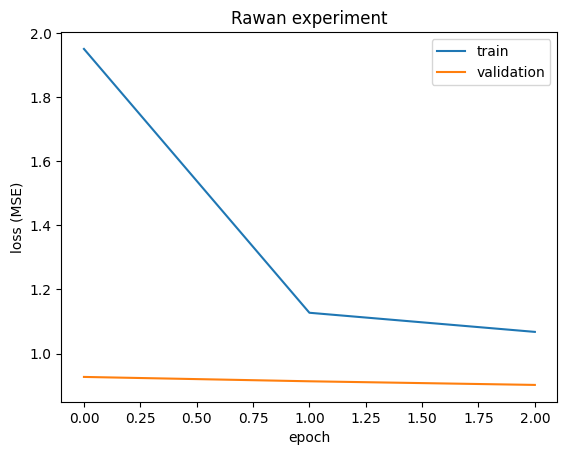

In [31]:
plt.plot(rawan_history.history["loss"], label="train")
plt.plot(rawan_history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (MSE)")
plt.title("Rawan experiment")
plt.legend()
plt.show()

### Comparison: Base Model vs Norah vs Shaden vs Raghad vs Basma vs Rawan


                 RMSE     MAE  ROC-AUC (liked)  Epochs
Shaden         0.9205  0.7261           0.7820    41.0
Raghad         0.9211  0.7246           0.7823    50.0
Norah          0.9240  0.7270           0.7799    34.0
Basma          0.9307  0.7346           0.7728    21.0
Base ANN       0.9393  0.7474           0.7688     6.0
Rawan          0.9502  0.7573           0.7626     3.0
Movie average  1.0158  0.8106           0.7135     0.0


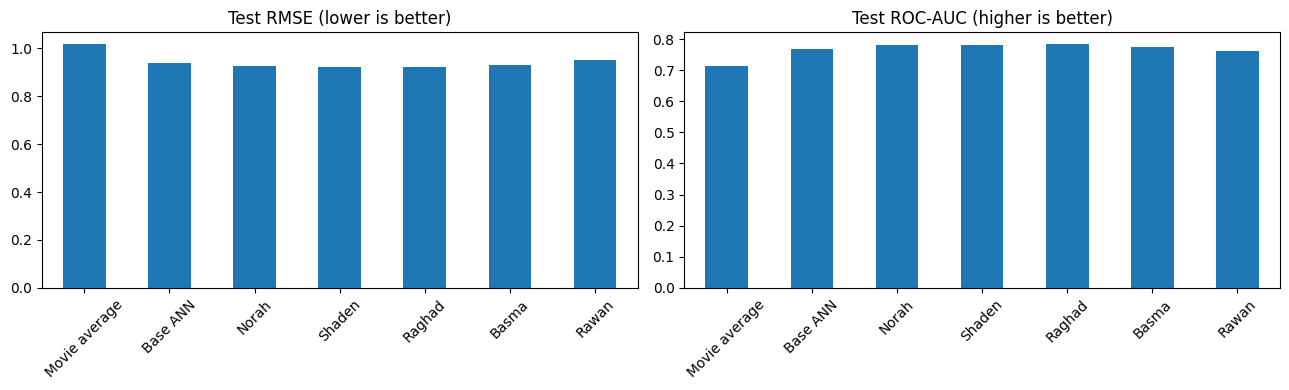

In [32]:
comparison_all = pd.DataFrame({
    "Movie average": {"RMSE": results.loc["Movie average", "RMSE"], "MAE": results.loc["Movie average", "MAE"], "ROC-AUC (liked)": results.loc["Movie average", "ROC-AUC (liked)"], "Epochs": 0},
    "Base ANN": {"RMSE": results.loc["Base ANN", "RMSE"], "MAE": results.loc["Base ANN", "MAE"], "ROC-AUC (liked)": results.loc["Base ANN", "ROC-AUC (liked)"], "Epochs": len(history.history["loss"])},
    "Norah": {"RMSE": rmse(y_test, my_pred), "MAE": mean_absolute_error(y_test, my_pred), "ROC-AUC (liked)": roc_auc_score(liked, my_pred), "Epochs": len(my_history.history["loss"])},
    "Shaden": {"RMSE": rmse(y_test, shaden_pred), "MAE": mean_absolute_error(y_test, shaden_pred), "ROC-AUC (liked)": roc_auc_score(liked, shaden_pred), "Epochs": len(shaden_history.history["loss"])},
    "Raghad": {"RMSE": rmse(y_test, exp_pred), "MAE": mean_absolute_error(y_test, exp_pred), "ROC-AUC (liked)": roc_auc_score(liked, exp_pred), "Epochs": len(exp_history.history["loss"])},
    "Basma": {"RMSE": rmse(y_test, basma_pred), "MAE": mean_absolute_error(y_test, basma_pred), "ROC-AUC (liked)": roc_auc_score(liked, basma_pred), "Epochs": len(basma_history.history["loss"])},
    "Rawan": {"RMSE": rmse(y_test, rawan_pred), "MAE": mean_absolute_error(y_test, rawan_pred), "ROC-AUC (liked)": roc_auc_score(liked, rawan_pred), "Epochs": len(rawan_history.history["loss"])},
}).T
print(comparison_all.round(4).sort_values("RMSE"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
comparison_all["RMSE"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Test RMSE (lower is better)")
axes[0].tick_params(axis="x", rotation=45)
comparison_all["ROC-AUC (liked)"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Test ROC-AUC (higher is better)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 12. Limitations
- **Cold start:** a new user or a new movie has no embedding, so the model cannot score it until it has some ratings.
- The model only uses ids and ratings: no movie genre, description or user age.
- A rating is not the same as an interaction: users mostly rate movies they chose to watch, so the data is biased toward movies they expected to like.
- MovieLens 100K is small and old (1990s movies), so results may differ on a modern catalog.